# Run analysis: `run-5_baseline-all-feat-purged-5-fold-val-retrain`

Test-period analysis of a rolling-window training run. Compared against the baseline run `run-4_baseline-sel-feat-purged-5-fold-val-retrain`.

Reads the run's `results_lgbm.json`, `predictions/` and `curves/`. Saves every
figure to `plots/analysis_*.png`. Generated by the `analyze-ts48-results`
skill; re-run top to bottom.

Sections:
1. Daily metrics: Pearson IC, Rank IC (Spearman), daily Kendall, Q5−Q1
2. Per-window summary: ICIR, Newey–West t, train/val/test R², cost
3. Plots: IC over time, cumulative IC, per-window metrics, R², quintiles,
   calibration
4. Finer grain: months and robust summaries
5. Ex-ante regimes
6. What changed vs the baseline: setup differences, automatic script diff,
   row and feature counts (only if a baseline is set)
7. Comparison with the baseline: paired daily differences on the same stocks
   and dates (only if a baseline is set)
8. Findings, summary and hypotheses (hypotheses only with a baseline)

**Ground rules** (from the baseline analysis, `claude/project-notes.md`):
- **Ranking and magnitude both matter.** The predictions feed a portfolio
  optimizer. Rank IC is the robust ranking measure (Pearson IC is inflated
  by fat-tailed labels); calibration slope, R² and RMSE judge magnitudes.
- **The label** is roughly a 5-day forward residual return. No further
  financial meaning is attached; values are in label units.
- **Significance uses Newey–West t.** Overlapping 5-day labels make daily
  ICs autocorrelated, so naive t-stats are ~1.7× too high.
- **Months are diagnostics.** ~20 days is only ~5 independent days, and
  months are never excluded from headline numbers.
- **Regimes use only information known at T.**
- **Comparisons are paired** on the same (Date, Code) rows.
- **The final reserved window** is evaluated only once, at the end of the
  project.


In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch
from scipy import stats

# The notebook lives in the run folder; VS Code runs it from there.
RUN_DIR = Path.cwd()
BASELINE_DIR = Path("/workspaces/TimeSeries48/runs/run-4_baseline-sel-feat-purged-5-fold-val-retrain")  # Path to the baseline run folder, or None (set by the skill).
assert (RUN_DIR / "results_lgbm.json").exists(), f"Not a run folder: {RUN_DIR}"
COMPARE = BASELINE_DIR is not None and BASELINE_DIR.resolve() != RUN_DIR.resolve()
DATA_FILE = RUN_DIR.parents[1] / "data.parquet"
PLOTS_DIR = RUN_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# Fixed categorical order, never cycled: one colour per window (7th = final window).
WINDOW_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
SPLIT_COLORS = {"train": "#52514e", "val": "#6250d6", "test": "#e34948"}
MODEL_COLORS = {"baseline": "#8f8e88", "run": "#2a78d6"}
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "legend.frameon": False,
})
warnings.filterwarnings("ignore", message=".*non-interactive.*")


def save(fig, name: str) -> None:
    """Save a figure to plots/analysis_<name>.png, then show it."""
    fig.savefig(PLOTS_DIR / f"analysis_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


def newey_west_t(x: np.ndarray, lags: int = 4) -> float:
    """t-statistic of mean(x) with a Newey–West (Bartlett-weighted) standard error."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    e = x - x.mean()
    n = len(x)
    var = e @ e / n
    for lag in range(1, min(lags, n - 1) + 1):
        var += 2 * (1 - lag / (lags + 1)) * (e[lag:] @ e[:-lag]) / n
    return float(x.mean() / np.sqrt(var / n))


def nw_ci(x: np.ndarray) -> float:
    """Half-width of a 95% confidence interval for mean(x), Newey–West (4 lags)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    t = newey_west_t(x)
    return float(1.96 * abs(x.mean() / t)) if t else float("nan")


def find_files(run_dir: Path, kind: str, pattern: str) -> list[Path]:
    """Files in run_dir/<kind>/ (current layout) or run_dir/ (early runs' flat layout)."""
    sub = run_dir / kind
    files = sorted(sub.glob(pattern)) if sub.is_dir() else []
    return files or sorted(run_dir.glob(pattern))


def load_run(run_dir: Path) -> tuple[list[dict], pl.DataFrame, dict[int, dict]]:
    """Results, test predictions (with a 1-based `window` column) and learning curves."""
    results = json.loads((run_dir / "results_lgbm.json").read_text())
    start_to_window = {r["test_start"]: k + 1 for k, r in enumerate(results)}

    def window_of(path: Path) -> int:
        return start_to_window[re.search(r"_test_(\d{4}-\d{2}-\d{2})_", path.name)[1]]

    preds = pl.concat([
        pl.read_parquet(f).with_columns(pl.lit(window_of(f)).cast(pl.Int32).alias("window"))
        for f in find_files(run_dir, "predictions", "predictions_*.parquet")
    ]).sort(["window", "Date", "Code"])
    curves = {window_of(f): json.loads(f.read_text())
              for f in find_files(run_dir, "curves", "curves_*.json")}
    return results, preds, curves


def daily_metrics(preds: pl.DataFrame) -> tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]:
    """Per-date IC, Rank IC, Kendall and Q5−Q1; plus quintile means and preds with quintiles."""
    daily = (
        preds.group_by(["window", "Date"], maintain_order=True)
        .agg(
            pl.corr("Prediction", "label").alias("ic"),
            pl.corr("Prediction", "label", method="spearman").alias("rank_ic"),
            pl.len().alias("n"),
        )
        .sort(["window", "Date"])
    )
    kendall = [
        stats.kendalltau(d["Prediction"].to_numpy(), d["label"].to_numpy()).statistic
        for d in preds.sort(["window", "Date"]).partition_by(["window", "Date"], maintain_order=True)
    ]
    daily = daily.with_columns(pl.Series("kendall", kendall))
    key = ["window", "Date"]
    preds = preds.with_columns(
        ((pl.col("Prediction").rank("ordinal").over(key).cast(pl.Int64) - 1) * 5
         // pl.len().over(key) + 1).alias("quintile")
    )
    quint_daily = preds.group_by(["window", "Date", "quintile"]).agg(
        pl.col("label").mean().alias("label_mean")
    )
    spread = (
        quint_daily.pivot(on="quintile", index=["window", "Date"], values="label_mean")
        .select("window", "Date", (pl.col("5") - pl.col("1")).alias("q5_minus_q1"))
    )
    daily = daily.join(spread, on=["window", "Date"]).sort(["window", "Date"])
    return daily, quint_daily, preds


In [2]:
results, preds, curves = load_run(RUN_DIR)
n_windows = len(results)
assert preds["window"].n_unique() == n_windows, "predictions missing for some windows"
print(f"RUN {RUN_DIR.name}: {n_windows} windows, {preds.height:,} test rows, "
      f"{preds['Date'].n_unique()} test dates ({preds['Date'].min()} -> {preds['Date'].max()})")
if len(curves) != n_windows:
    print(f"  note: learning curves found for {len(curves)} of {n_windows} windows")

if COMPARE:
    b_results, b_preds, b_curves = load_run(BASELINE_DIR)
    print(f"BASELINE {BASELINE_DIR.name}: {len(b_results)} windows, {b_preds.height:,} rows, "
          f"{b_preds['Date'].min()} -> {b_preds['Date'].max()}")
    run_windows = {(r["test_start"], r["test_end"]) for r in results}
    base_windows = {(r["test_start"], r["test_end"]) for r in b_results}
    if run_windows != base_windows:
        print("  WARNING: test windows differ between run and baseline; "
              "the comparison uses only their common (Date, Code) rows.")


RUN run-5_baseline-all-feat-purged-5-fold-val-retrain: 6 windows, 2,028,817 test rows, 720 test dates (2022-12-29 -> 2025-12-18)
BASELINE run-4_baseline-sel-feat-purged-5-fold-val-retrain: 6 windows, 2,028,817 rows, 2022-12-29 -> 2025-12-18


## 1. Daily metrics

Every metric is computed **within each test date** (stocks vs stocks on the
same day), then summarised per window.

- **IC:** Pearson correlation of prediction and label. Uses magnitudes, so
  it is sensitive to extreme stocks.
- **Rank IC:** Spearman correlation, i.e. ordering only. The robust ranking
  metric (magnitudes are judged separately, by calibration and R²).
- **Kendall:** pairwise ordering agreement; numerically ≈ 0.68 × Rank IC.
- **Q5−Q1:** mean label of the top prediction quintile minus the bottom
  quintile, in label units (the label is roughly a 5-day forward residual
  return; no further financial meaning is attached). Gross, not a profit.


In [3]:
daily, quint_daily, preds = daily_metrics(preds)
daily.head()


window,Date,ic,rank_ic,n,kendall,q5_minus_q1
i32,date,f64,f64,u32,f64,f32
1,2022-12-29,0.073113,0.01995,2721,0.011871,0.001738
1,2022-12-30,0.066376,0.018725,2722,0.012216,0.003281
1,2023-01-03,0.119315,0.033903,2724,0.020638,0.003403
1,2023-01-04,0.073172,0.019269,2724,0.011321,0.003347
1,2023-01-05,0.031123,0.037034,2724,0.023931,0.003087


## 2. Per-window summary

- **ICIR** = mean(IC) / std(IC), unscaled, so it is comparable across windows.
  The training script's `ir` multiplies by √days and is really a naive
  t-statistic.
- **t (naive)** assumes independent days. **t (NW)** uses Newey–West standard
  errors with 4 lags, needed because the 5-day labels overlap. **IC ac1** is
  the lag-1 autocorrelation of daily IC.
- **train / val R²** at `best_iteration`, from the learning curves; **test
  R²** from the results. val ≫ test can mean the interleaved-validation leak
  (I-1) **or** a hard test period: check months (section 4) before blaming
  the leak.
- R² and calibration are meaningful only if predictions are in label units.
  They are not if the run trains on transformed labels (e.g. rank-Gauss).


In [4]:
def curve_at(c: dict | None, split: str, metric: str) -> float:
    """A learning-curve metric at best_iteration; NaN if it wasn't recorded."""
    if not c or not c.get("best_iteration"):
        return float("nan")
    values = c["curves"].get(split, {}).get(metric)
    best = c["best_iteration"]
    return values[best - 1] if values and best <= len(values) else float("nan")


rows = []
for w in range(1, n_windows + 1):
    d = daily.filter(pl.col("window") == w)
    ic = d["ic"].drop_nans().to_numpy()
    r = results[w - 1]
    rows.append({
        "window": w,
        "test": f"{r['test_start']} -> {r['test_end']}",
        "days": len(ic),
        "features": r.get("features"),
        "best_iter": r.get("best_iteration"),
        "IC": ic.mean(),
        "RankIC": d["rank_ic"].mean(),
        "Kendall(daily)": d["kendall"].mean(),
        "ICIR": ic.mean() / ic.std(ddof=1),
        "IC>0 %": 100 * (ic > 0).mean(),
        "t(naive)": ic.mean() / ic.std(ddof=1) * np.sqrt(len(ic)),
        "t(NW)": newey_west_t(ic),
        "IC ac1": np.corrcoef(ic[1:], ic[:-1])[0, 1],
        "train R2": curve_at(curves.get(w), "train", "r2"),
        "val R2": curve_at(curves.get(w), "val", "r2"),
        "test R2": r.get("r2", float("nan")),
        "Q5-Q1": d["q5_minus_q1"].mean(),
        "runtime s": r.get("runtime", float("nan")),
        "peak GB": r.get("peak_memory_GB", r.get("peak_memory_gb", float("nan"))),
    })
summary = pl.DataFrame(rows)
all_ic = daily["ic"].drop_nans().to_numpy()
all_ric = daily["rank_ic"].drop_nans().to_numpy()
print(f"All windows: RankIC={all_ric.mean():.4f} (t NW {newey_west_t(all_ric):.1f})  "
      f"IC={all_ic.mean():.4f}  ICIR={all_ic.mean() / all_ic.std(ddof=1):.2f}  "
      f"t(NW)={newey_west_t(all_ic):.1f}  IC>0 on {100 * (all_ic > 0).mean():.0f}% of days")
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, tbl_width_chars=250):
    display(summary)  # noqa: F821  (IPython built-in)


All windows: RankIC=0.0631 (t NW 14.5)  IC=0.0985  ICIR=1.37  t(NW)=21.1  IC>0 on 92% of days


window,test,days,features,best_iter,IC,RankIC,Kendall(daily),ICIR,IC>0 %,t(naive),t(NW),IC ac1,train R2,val R2,test R2,Q5-Q1,runtime s,peak GB
i64,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""2022-12-29 -> 2023-06-30""",120,48,374,0.0918,0.0485,0.0321,1.3248,95.8333,14.5123,8.6734,0.6762,0.0159,0.0058,0.0090,0.0051,100.2901,2.0750
2,"""2023-07-03 -> 2023-12-25""",120,48,512,0.1050,0.0655,0.0442,1.5354,93.3333,16.8193,10.1452,0.6165,0.0203,0.0061,0.0111,0.0079,125.5045,1.5685
3,"""2023-12-26 -> 2024-06-27""",120,48,408,0.1374,0.0930,0.0634,1.6927,94.1667,18.5429,10.3514,0.7440,0.0235,0.0093,0.0179,0.0135,108.6680,1.5814
4,"""2024-06-28 -> 2024-12-23""",120,48,563,0.0962,0.0571,0.0374,1.2968,88.3333,14.2055,8.3895,0.6749,0.0297,0.0107,0.0050,0.0073,139.0200,1.5818
5,"""2024-12-24 -> 2025-06-25""",120,48,286,0.0742,0.0574,0.0386,1.1954,88.3333,13.0947,7.9745,0.5927,0.0214,0.0079,0.0040,0.0082,87.1682,1.5915
6,"""2025-06-26 -> 2025-12-18""",120,48,371,0.0863,0.0572,0.0388,1.4588,93.3333,15.9799,10.5884,0.4873,0.0188,0.0058,0.0071,0.0092,102.6877,1.5814


## 3. Plots

- **IC over time:** daily values (grey) and a 20-day rolling mean per window
  (colour).
- **Cumulative IC:** the slope is the IC level. Flat stretches are periods
  where the signal stopped working. Not a profit curve.
- **Per-window metrics and R²:** train / val / test R² side by side.
- **Quintiles:** mean label per prediction quintile. In the baseline the edge
  sits in Q1: volatile, lottery-like stocks drift down, while big winners are
  news-driven and unpredictable.
- **Calibration:** 20 prediction bins per window, (mean prediction, mean
  label). On y = x means calibrated; flatter means overconfident.


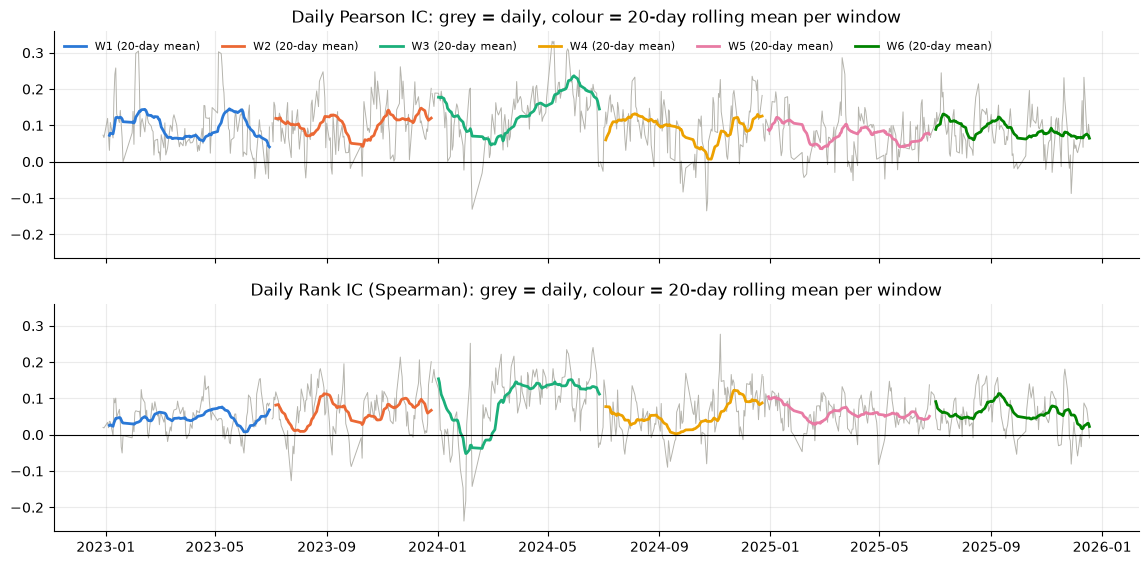

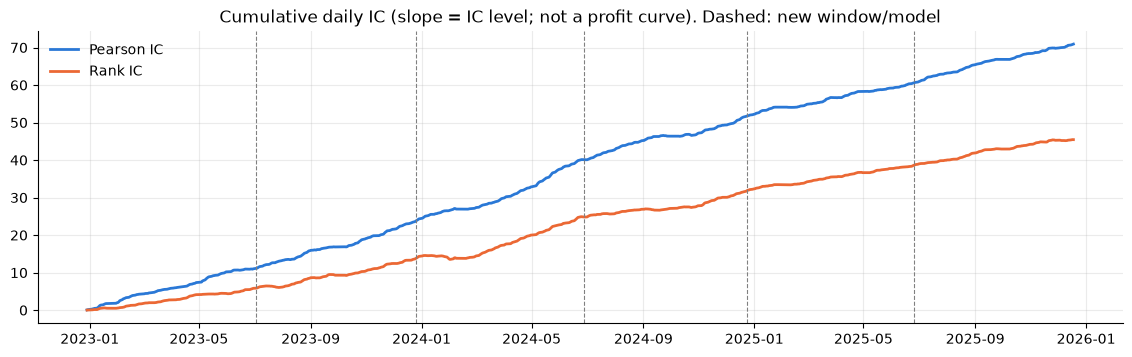

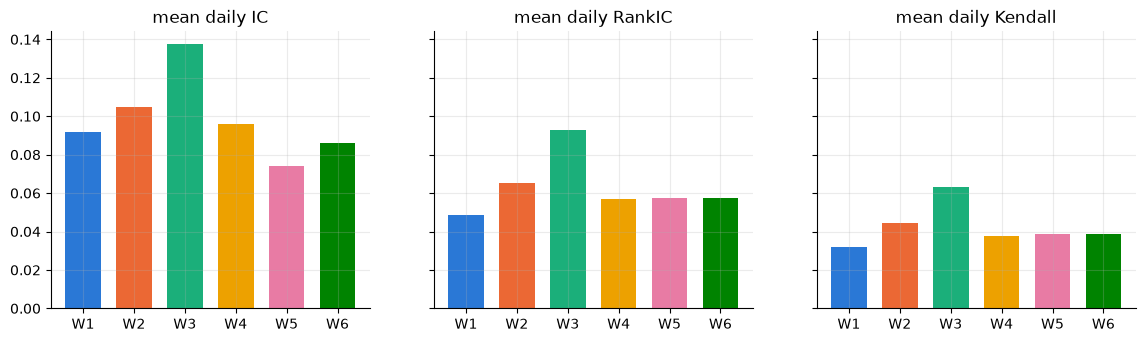

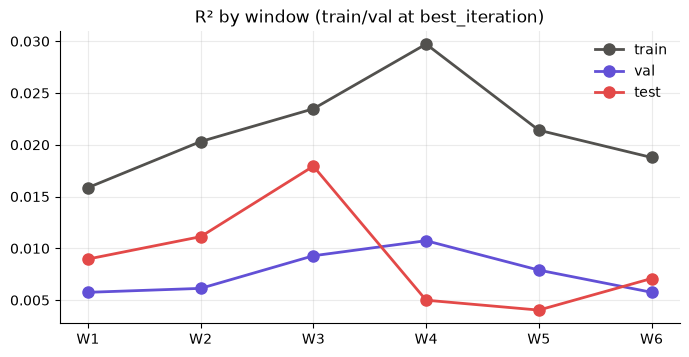

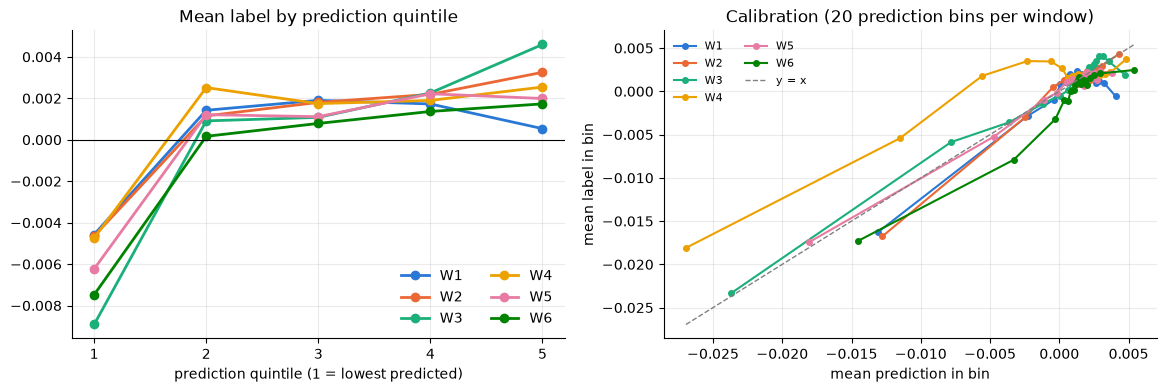

shape: (6, 6)
┌────────┬───────────┬──────────┬──────────┬──────────┬──────────┐
│ window ┆ 1         ┆ 2        ┆ 3        ┆ 4        ┆ 5        │
│ ---    ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i32    ┆ f32       ┆ f32      ┆ f32      ┆ f32      ┆ f32      │
╞════════╪═══════════╪══════════╪══════════╪══════════╪══════════╡
│ 1      ┆ -0.004572 ┆ 0.001422 ┆ 0.001902 ┆ 0.001727 ┆ 0.000537 │
│ 2      ┆ -0.004645 ┆ 0.001151 ┆ 0.001803 ┆ 0.002189 ┆ 0.003253 │
│ 3      ┆ -0.008913 ┆ 0.000909 ┆ 0.00108  ┆ 0.002259 ┆ 0.004596 │
│ 4      ┆ -0.004742 ┆ 0.002516 ┆ 0.001743 ┆ 0.001898 ┆ 0.002543 │
│ 5      ┆ -0.006233 ┆ 0.001211 ┆ 0.001112 ┆ 0.002219 ┆ 0.00199  │
│ 6      ┆ -0.007478 ┆ 0.000165 ┆ 0.000787 ┆ 0.001364 ┆ 0.001731 │
└────────┴───────────┴──────────┴──────────┴──────────┴──────────┘


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, sharey=True)
for ax, col, name in zip(axes, ["ic", "rank_ic"], ["Pearson IC", "Rank IC (Spearman)"]):
    for w in range(1, n_windows + 1):
        d = daily.filter(pl.col("window") == w)
        x = d["Date"].to_numpy()
        ax.plot(x, d[col], color="#b5b4ad", lw=0.7)
        ax.plot(x, d[col].rolling_mean(20, min_samples=5),
                color=WINDOW_COLORS[w - 1], label=f"W{w} (20-day mean)")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Daily {name}: grey = daily, colour = 20-day rolling mean per window")
axes[0].legend(ncol=n_windows, loc="upper left", fontsize=8)
save(fig, "ic_over_time")

fig, ax = plt.subplots(figsize=(14, 3.8))
x = daily["Date"].to_numpy()
ax.plot(x, daily["ic"].fill_nan(0).cum_sum(), color=WINDOW_COLORS[0], label="Pearson IC")
ax.plot(x, daily["rank_ic"].fill_nan(0).cum_sum(), color=WINDOW_COLORS[1], label="Rank IC")
for w in range(2, n_windows + 1):
    ax.axvline(daily.filter(pl.col("window") == w)["Date"][0], color="gray", ls="--", lw=0.8)
ax.set_title("Cumulative daily IC (slope = IC level; not a profit curve). Dashed: new window/model")
ax.legend()
save(fig, "cumulative_ic")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
wins = summary["window"].to_list()
for ax, col in zip(axes, ["IC", "RankIC", "Kendall(daily)"]):
    ax.bar(wins, summary[col], color=WINDOW_COLORS[:n_windows], width=0.7)
    ax.set_title(f"mean daily {col.replace('(daily)', '')}")
    ax.set_xticks(wins, [f"W{w}" for w in wins])
save(fig, "metrics_by_window")

fig, ax = plt.subplots(figsize=(8, 3.8))
for split, col in [("train", "train R2"), ("val", "val R2"), ("test", "test R2")]:
    ax.plot(wins, summary[col], "o-", color=SPLIT_COLORS[split], label=split, ms=8)
ax.set_xticks(wins, [f"W{w}" for w in wins])
ax.set_title("R² by window (train/val at best_iteration)")
ax.legend()
save(fig, "r2_by_window")

quint = (
    quint_daily.group_by(["window", "quintile"]).agg(pl.col("label_mean").mean())
    .sort(["window", "quintile"])
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for w in range(1, n_windows + 1):
    q = quint.filter(pl.col("window") == w)
    axes[0].plot(q["quintile"], q["label_mean"], "o-", color=WINDOW_COLORS[w - 1], label=f"W{w}", ms=6)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xlabel("prediction quintile (1 = lowest predicted)")
axes[0].set_title("Mean label by prediction quintile")
axes[0].legend(ncol=2)
binned = (
    preds.with_columns(
        ((pl.col("Prediction").rank("ordinal").over("window").cast(pl.Int64) - 1) * 20
         // pl.len().over("window")).alias("bin")
    )
    .group_by(["window", "bin"]).agg(pl.col("Prediction").mean(), pl.col("label").mean())
    .sort(["window", "bin"])
)
for w in range(1, n_windows + 1):
    b = binned.filter(pl.col("window") == w)
    axes[1].plot(b["Prediction"], b["label"], "o-", color=WINDOW_COLORS[w - 1], label=f"W{w}", ms=4, lw=1.5)
lim = [binned["Prediction"].min(), binned["Prediction"].max()]
axes[1].plot(lim, lim, "--", color="gray", lw=1, label="y = x")
axes[1].set_xlabel("mean prediction in bin")
axes[1].set_ylabel("mean label in bin")
axes[1].set_title("Calibration (20 prediction bins per window)")
axes[1].legend(ncol=2, fontsize=8)
save(fig, "quintiles_calibration")
print(quint.pivot(on="quintile", index="window", values="label_mean"))


## 4. Finer grain: months and robust summaries

A weak window can mean broad weakness, or a few bad stretches inside an
otherwise good period. This section separates the two.

**How to read it.** A single month (~20 test days, with strongly
autocorrelated daily ICs) is worth only ~5 independent days. One bad month
proves little; look for **patterns**: months that are bad across several
models, or runs of weak months. Headline metrics stay full-period. Months are
never excluded after the fact (that would be cherry-picking).

- **Top panel:** monthly mean daily **Rank IC** (bars, colour = window) and
  **Pearson IC** (black dots). Dots far above their bar mark months where the
  signal worked only through a few extreme stocks.
- **Bottom panel:** monthly **calibration slope**, the regression slope of
  label on prediction. 1 means magnitudes are right; below 1 means
  overconfident (predictions too spread out); below 0.5 (dotted) means
  strongly overconfident.
- **Robust table:** median daily IC and a 10%-trimmed mean. If they are close
  to the mean, the window's result isn't driven by a few extreme days.


window,month,days,IC,RankIC,IC>0 %,R2,slope
i32,str,u32,f64,f64,f64,f64,f64
1,"""2022-12""",2,0.070,0.019,100.000,0.003,0.858
1,"""2023-01""",16,0.115,0.031,93.750,0.011,1.424
1,"""2023-02""",20,0.118,0.061,100.000,0.016,1.473
1,"""2023-03""",23,0.065,0.042,100.000,0.004,0.943
1,"""2023-04""",19,0.080,0.074,100.000,0.006,1.228
1,"""2023-05""",20,0.143,0.016,100.000,0.018,1.688
1,"""2023-06""",20,0.041,0.068,80.000,-0.000,0.500
2,"""2023-07""",21,0.103,0.014,100.000,0.010,1.146
2,"""2023-08""",23,0.115,0.105,86.957,0.013,1.479


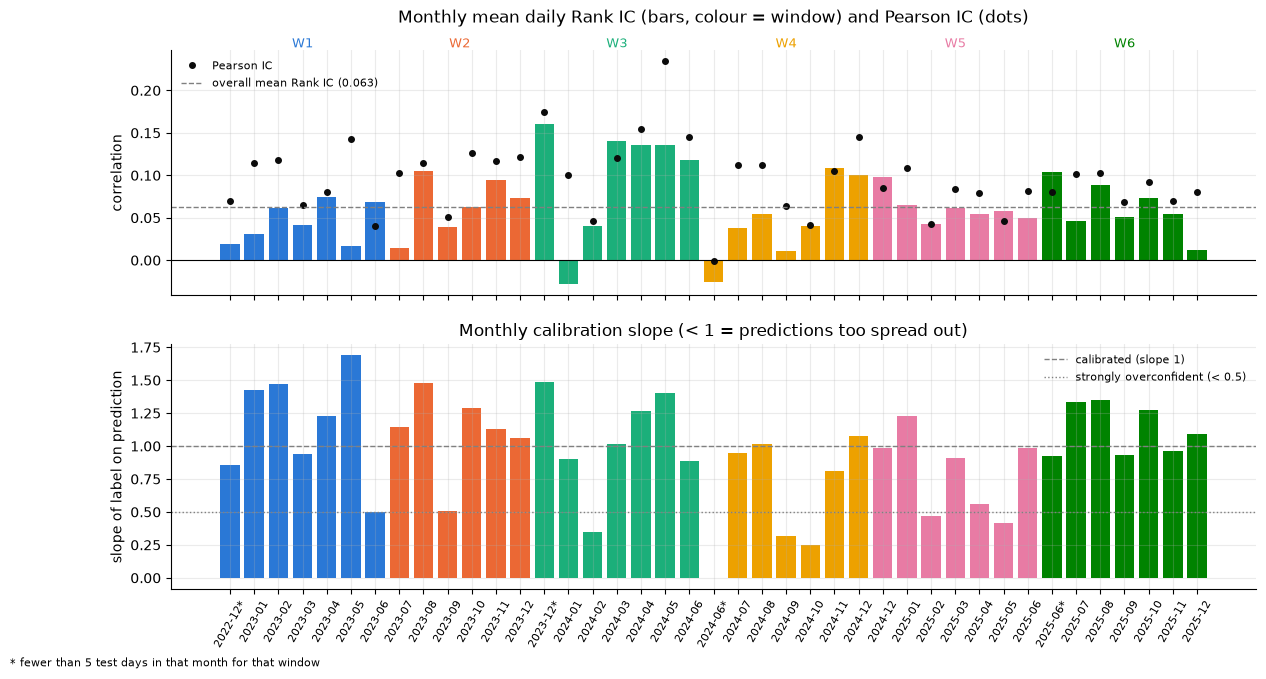

window,IC mean,IC median,IC trimmed 10%,RankIC median,RankIC>0 %
i32,f64,f64,f64,f64,f64
1,0.0918,0.0834,0.0847,0.0501,85.0000
2,0.1050,0.1025,0.1045,0.0645,84.1667
3,0.1374,0.1431,0.1392,0.1133,86.6667
4,0.0962,0.1053,0.1000,0.0569,80.8333
5,0.0742,0.0847,0.0729,0.0554,93.3333
6,0.0863,0.0855,0.0853,0.0553,85.0000


In [6]:
def month_stats(frame: pl.DataFrame, by: list[str]) -> pl.DataFrame:
    """Pooled R² and calibration slope per group of rows."""
    return frame.group_by(by).agg(
        (1 - ((pl.col("label") - pl.col("Prediction")) ** 2).sum()
         / ((pl.col("label") - pl.col("label").mean()) ** 2).sum()).alias("R2"),
        (pl.cov("Prediction", "label") / pl.col("Prediction").var()).alias("slope"),
    )


preds = preds.with_columns(pl.col("Date").dt.strftime("%Y-%m").alias("month"))
daily = daily.with_columns(pl.col("Date").dt.strftime("%Y-%m").alias("month"))
monthly = (
    daily.group_by(["window", "month"]).agg(
        pl.len().alias("days"),
        pl.col("ic").mean().alias("IC"),
        pl.col("rank_ic").mean().alias("RankIC"),
        (100 * (pl.col("ic") > 0).mean()).alias("IC>0 %"),
    )
    .join(month_stats(preds, ["window", "month"]), on=["window", "month"])
    .sort(["month", "window"])
)
with pl.Config(tbl_rows=-1, float_precision=3):
    display(monthly)  # noqa: F821

x = np.arange(monthly.height)
colors = [WINDOW_COLORS[w - 1] for w in monthly["window"]]
labels_x = [m if d >= 5 else f"{m}*" for m, d in zip(monthly["month"], monthly["days"])]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].bar(x, monthly["RankIC"], color=colors, width=0.8)
axes[0].plot(x, monthly["IC"], "o", color="#0b0b0b", ms=4, label="Pearson IC")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axhline(daily["rank_ic"].mean(), color="gray", ls="--", lw=1,
                label=f"overall mean Rank IC ({daily['rank_ic'].mean():.3f})")
axes[0].set_ylabel("correlation")
axes[0].set_title("Monthly mean daily Rank IC (bars, colour = window) and Pearson IC (dots)", pad=20)
axes[0].legend(loc="upper left", fontsize=8)
axes[1].bar(x, monthly["slope"], color=colors, width=0.8)
axes[1].axhline(1, color="gray", ls="--", lw=1, label="calibrated (slope 1)")
axes[1].axhline(0.5, color="gray", ls=":", lw=1, label="strongly overconfident (< 0.5)")
axes[1].set_ylabel("slope of label on prediction")
axes[1].set_title("Monthly calibration slope (< 1 = predictions too spread out)")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_xticks(x, labels_x, rotation=60, fontsize=8)
# Window labels above the top panel.
for w in range(1, n_windows + 1):
    idx = np.flatnonzero(monthly["window"].to_numpy() == w)
    axes[0].annotate(f"W{w}", (idx.mean(), 1.0), xycoords=("data", "axes fraction"),
                     ha="center", va="bottom", fontsize=9, color=WINDOW_COLORS[w - 1])
fig.text(0.01, 0.0, "* fewer than 5 test days in that month for that window", fontsize=8)
save(fig, "monthly")

robust = daily.group_by("window").agg(
    pl.col("ic").mean().alias("IC mean"),
    pl.col("ic").median().alias("IC median"),
    pl.col("ic").filter(
        pl.col("ic").is_between(pl.col("ic").quantile(0.1), pl.col("ic").quantile(0.9))
    ).mean().alias("IC trimmed 10%"),
    pl.col("rank_ic").median().alias("RankIC median"),
    (100 * (pl.col("rank_ic") > 0).mean()).alias("RankIC>0 %"),
).sort("window")
with pl.Config(float_precision=4):
    display(robust)  # noqa: F821


## 5. Ex-ante regimes: does performance depend on observable conditions?

**What a regime split is.** Each test day is put into a group ("regime")
according to the market conditions on that day, and performance is compared
across groups.

**Why ex-ante (known in advance).** A regime split is only useful if you could
have *acted* on it: trust or size the signal more in some conditions, add the
condition as a model feature, or check whether a model variant (e.g. history
features) helps mainly in certain conditions. So each day's regime is built
**only from information available at the close of day T**. Labelling months
after the fact ("that was a crash month") can explain the past, but nobody
could have traded on it, and it invites cherry-picking. A regime split does
**not** try to foresee shocks. Finding that the regime *can't* flag the bad
periods is itself a useful (negative) result.

**How the regime is built.**
1. *Dispersion* = the cross-sectional std of the label on a date: how
   differently stocks moved. Labels are factor-adjusted, so this is
   stock-specific dispersion, **not** market volatility.
2. *Trailing dispersion* at T = the mean dispersion over dates T−26 … T−7.
   Those labels are fully realized by day T, so there is no look-ahead.
3. *Percentile* = where today's trailing dispersion ranks among the previous
   ~250 trading days (one year, at least 120 needed). Below the 33rd
   percentile is **calm**, above the 67th is **turbulent**, and in between is
   **normal**. Relative to the past year, so the thresholds adapt over time.

**How to read the charts.**
- *Timeline* (three rows sharing the date axis):
  1. Daily dispersion (thin) and the trailing measure (bold). Dotted lines
     mark the largest dispersion spikes. Note how the trailing measure reacts
     only after a spike: shock onsets look calm ex-ante.
  2. The percentile and the 1/3 and 2/3 thresholds. Background shading =
     regime (light = calm, dark = turbulent), the same in all rows.
  3. Daily Rank IC (faint) and its 20-day mean (bold), against the regime
     shading.
- *Summary*: left, mean daily Rank IC per regime, with Newey–West 95%
  confidence intervals and the number of days and of distinct **episodes**
  (separate runs of ≥ 5 days). Few episodes means weak evidence, however many
  days they cover. Right, the same per window: if the effect is real it
  should appear in most windows, not just one.

**In the comparison (section 6)** the same regimes are used to check *where*
a variant helps: e.g. whether history features mainly help after dispersion
spikes.


In [7]:
LAG, SPAN, HISTORY, MIN_HISTORY = 7, 20, 250, 120
per_day = (
    pl.read_parquet(DATA_FILE, columns=["Date", "label"]).drop_nulls()
    .group_by("Date").agg(pl.col("label").std().alias("std"))
    .sort("Date")
)
REGIMES = ["calm", "normal", "turbulent"]
REGIME_COLORS = {"calm": "#cde2fb", "normal": "#6da7ec", "turbulent": "#184f95"}

per_day = per_day.sort("Date").with_columns(
    pl.col("std").shift(LAG).rolling_mean(SPAN).alias("trail_disp")   # dates T-26 ... T-7
)
td = per_day["trail_disp"].fill_null(np.nan).to_numpy()
pct = np.full(len(td), np.nan)
for i in range(len(td)):
    past = td[max(0, i - HISTORY):i]
    past = past[~np.isnan(past)]
    if len(past) >= MIN_HISTORY and not np.isnan(td[i]):
        pct[i] = (past < td[i]).mean()      # percentile vs the previous ~1 year
per_day = per_day.with_columns(pl.Series("disp_pct", pct).fill_nan(None)).with_columns(
    pl.when(pl.col("disp_pct").is_null()).then(None)
    .when(pl.col("disp_pct") < 1 / 3).then(pl.lit("calm"))
    .when(pl.col("disp_pct") < 2 / 3).then(pl.lit("normal"))
    .otherwise(pl.lit("turbulent")).alias("regime")
)
day_regime = per_day.select("Date", "regime")
daily = daily.drop("regime", strict=False).join(day_regime, on="Date", how="left")
preds = preds.drop("regime", strict=False).join(day_regime, on="Date", how="left")
test_days = (
    daily.group_by("Date").agg(pl.col("rank_ic").mean(), pl.col("regime").first())
    .sort("Date")
)
print("test days without a regime (too little history):", test_days["regime"].null_count())


def episodes(frame: pl.DataFrame, min_len: int = 5) -> pl.DataFrame:
    """Contiguous runs of the same regime over consecutive test days."""
    runs = (
        frame.with_columns((pl.col("regime") != pl.col("regime").shift()).fill_null(True)
                           .cum_sum().alias("run"))
        .group_by("run", maintain_order=True)
        .agg(pl.col("regime").first(), pl.col("Date").first().alias("start"),
             pl.col("Date").last().alias("end"), pl.len().alias("days"))
    )
    return runs.filter(pl.col("days") >= min_len)


rows = []
eps = episodes(test_days.drop_nulls("regime"))
for r in REGIMES:
    d = daily.filter(pl.col("regime") == r)
    ric = d.sort("Date")["rank_ic"].drop_nans().to_numpy()
    rows.append({
        "regime": r, "days": d["Date"].n_unique(),
        "episodes (>=5 days)": eps.filter(pl.col("regime") == r).height,
        "RankIC": ric.mean(), "RankIC 95% CI ±": nw_ci(ric),
        "IC": d["ic"].mean(), "RankIC>0 %": 100 * (ric > 0).mean(),
        "Q5-Q1": d["q5_minus_q1"].mean(),
    })
by_regime = pl.DataFrame(rows)
by_window = (
    daily.drop_nulls("regime").group_by(["window", "regime"])
    .agg(pl.len().alias("days"), pl.col("rank_ic").mean().alias("RankIC"))
    .sort(["window", "regime"])
)
with pl.Config(float_precision=4, tbl_rows=-1):
    display(by_regime)  # noqa: F821
    display(by_window.pivot(on="regime", index="window", values=["days", "RankIC"]))  # noqa: F821


test days without a regime (too little history): 0


regime,days,episodes (>=5 days),RankIC,RankIC 95% CI ±,IC,RankIC>0 %,Q5-Q1
str,i64,i64,f64,f64,f64,f64,f64
"""calm""",283,8,0.0472,0.0129,0.0913,83.0389,0.0063
"""normal""",242,11,0.0596,0.0120,0.0865,88.0165,0.0079
"""turbulent""",195,3,0.0906,0.0179,0.1238,87.1795,0.0126


window,days_calm,days_normal,days_turbulent,RankIC_calm,RankIC_normal,RankIC_turbulent
i32,u32,u32,u32,f64,f64,f64
1,70,30,20,0.0447,0.0846,0.0079
2,99,21,null,0.0590,0.0961,null
3,28,3,89,-0.0047,0.1384,0.1222
4,7,42,71,0.0665,0.0234,0.0761
5,19,89,12,0.0517,0.0531,0.0983
6,60,57,3,0.0511,0.0657,0.0190


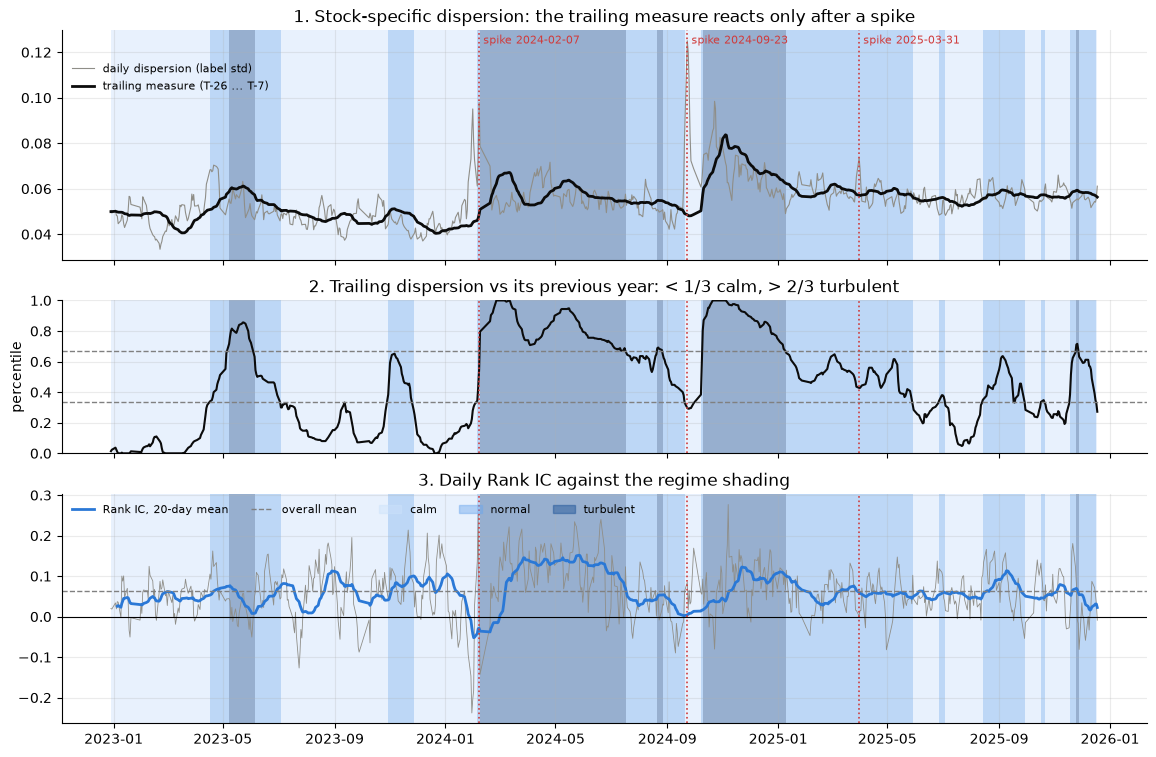

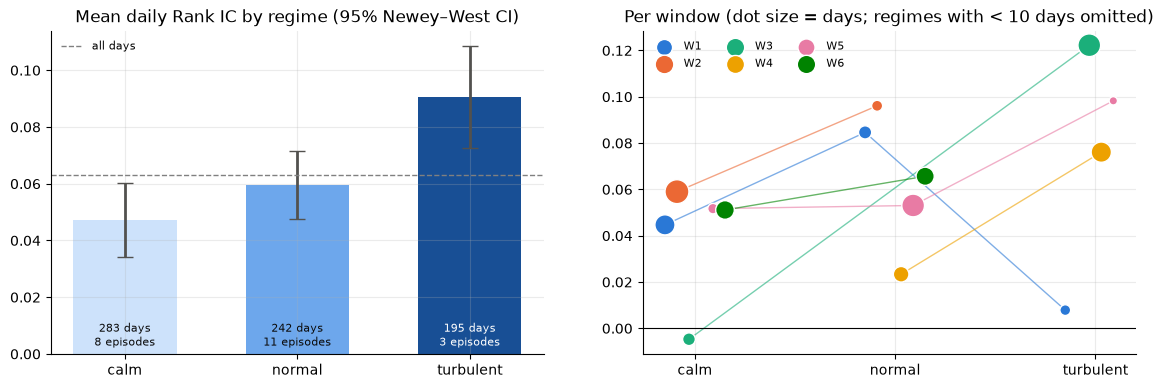

In [8]:
def shade(ax) -> None:
    """Shade the background by regime (all runs, including short ones)."""
    runs = episodes(test_days.drop_nulls("regime"), min_len=1)
    starts = runs["start"].to_list()
    ends = starts[1:] + [test_days["Date"].max()]
    for regime_name, s, e in zip(runs["regime"], starts, ends):
        ax.axvspan(s, e, color=REGIME_COLORS[regime_name], alpha=0.45, lw=0)


in_test = per_day.filter(pl.col("Date").is_between(test_days["Date"].min(), test_days["Date"].max()))
# Largest dispersion spikes in the test period, at least 60 days apart.
spikes = []
for row in in_test.sort("std", descending=True).iter_rows(named=True):
    if all(abs((row["Date"] - s).days) > 60 for s in spikes):
        spikes.append(row["Date"])
    if len(spikes) == 3:
        break

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 0.8, 1.2]})
dates = in_test["Date"].to_numpy()
axes[0].plot(dates, in_test["std"], color="#8f8e88", lw=0.8, label="daily dispersion (label std)")
axes[0].plot(dates, in_test["trail_disp"], color="#0b0b0b", lw=2, label="trailing measure (T-26 ... T-7)")
axes[0].set_title("1. Stock-specific dispersion: the trailing measure reacts only after a spike")
axes[1].plot(dates, in_test["disp_pct"], color="#0b0b0b", lw=1.5)
for level in (1 / 3, 2 / 3):
    axes[1].axhline(level, color="gray", ls="--", lw=1)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("percentile")
axes[1].set_title("2. Trailing dispersion vs its previous year: < 1/3 calm, > 2/3 turbulent")
t = test_days["Date"].to_numpy()
axes[2].plot(t, test_days["rank_ic"], color="#8f8e88", lw=0.6)
axes[2].plot(t, test_days["rank_ic"].rolling_mean(20, min_samples=5), color=WINDOW_COLORS[0],
             lw=2, label="Rank IC, 20-day mean")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].axhline(test_days["rank_ic"].mean(), color="gray", ls="--", lw=1, label="overall mean")
axes[2].set_title("3. Daily Rank IC against the regime shading")
for ax in axes:
    shade(ax)
    for s in spikes:
        ax.axvline(s, color="#d03b3b", ls=":", lw=1.2)
for s in spikes:
    axes[0].annotate(f"spike {s}", (s, 1.0), xycoords=("data", "axes fraction"),
                     ha="left", va="top", fontsize=8, color="#d03b3b", xytext=(3, -3),
                     textcoords="offset points")
from matplotlib.patches import Patch  # noqa: E402
regime_handles = [Patch(color=REGIME_COLORS[r], alpha=0.45, label=r) for r in REGIMES]
axes[0].legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, 0.9))
axes[2].legend(handles=axes[2].get_legend_handles_labels()[0] + regime_handles, loc="upper left",
               fontsize=8, ncol=5)
save(fig, "regime_timeline")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xs = np.arange(len(REGIMES))
axes[0].bar(xs, by_regime["RankIC"], color=[REGIME_COLORS[r] for r in REGIMES], width=0.6,
            yerr=by_regime["RankIC 95% CI ±"], capsize=6, ecolor="#52514e")
axes[0].axhline(daily["rank_ic"].mean(), color="gray", ls="--", lw=1, label="all days")
for xi, row in zip(xs, by_regime.iter_rows(named=True)):
    axes[0].annotate(f"{row['days']} days\n{row['episodes (>=5 days)']} episodes", (xi, 0),
                     textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8,
                     color="#0b0b0b" if row["regime"] != "turbulent" else "white")
axes[0].set_xticks(xs, REGIMES)
axes[0].set_title("Mean daily Rank IC by regime (95% Newey–West CI)")
axes[0].legend(loc="upper left", fontsize=8)
for w in range(1, n_windows + 1):
    bw = by_window.filter((pl.col("window") == w) & (pl.col("days") >= 10))
    xw = [REGIMES.index(r) + (w - (n_windows + 1) / 2) * 0.06 for r in bw["regime"]]
    axes[1].plot(xw, bw["RankIC"], "-", color=WINDOW_COLORS[w - 1], lw=1, alpha=0.6)
    axes[1].scatter(xw, bw["RankIC"], s=bw["days"] * 3, color=WINDOW_COLORS[w - 1],
                    edgecolor="white", linewidth=1, label=f"W{w}", zorder=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(xs, REGIMES)
axes[1].set_title("Per window (dot size = days; regimes with < 10 days omitted)")
axes[1].legend(ncol=3, fontsize=8, loc="upper left")
save(fig, "regimes")


## 6. What changed vs the baseline: no feature filter (all 48 features)

Baseline: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`. Run: `run-5_baseline-all-feat-purged-5-fold-val-retrain`.
Same protocol (purged 5-fold, stopping on the fold-mean validation R², retrain
on all history), parameters, seeds, windows and test universe (100% common
rows).

| Category | Baseline → run | Why | Expected effect |
|---|---|---|---|
| Features | `CORR_BAR` = 0.02 filter (per fold; final set re-selected on all history) → **all 48 features** (`SELECT_FEATURES = False`) | Selection was unstable across windows and folds (N-14). A linear, marginal filter can drop features the trees use non-linearly | Higher or equal skill; stable inputs; one hyperparameter fewer |

**Effective consequences:**
- Final features 34, 40, 40, 40, 34, 33 → 48 in every window (+8 … +15).
- Per-fold sets in run 4 ranged from 24 to 43 features.
- Tree counts 411, 453, 334, 402, 273, 350 → 374, 512, 408, 563, 286, 371.
  This is **not** a confound: run 5's models scored at run 4's tree counts
  differ by ≤ 0.0006 Rank IC (Findings 8).
- Runtime 603 s → 663 s (+10%); memory the same.

A single change.


In [9]:
assert COMPARE, "No baseline set: skip this section."
import difflib  # noqa: E402
import io  # noqa: E402
import tokenize  # noqa: E402


def code_without_comments(path: Path) -> list[str]:
    """Source lines with comments and blank lines removed (NOTE comments aren't setup changes)."""
    out, last_line = [], -1
    tokens = tokenize.generate_tokens(io.StringIO(path.read_text(encoding="utf-8")).readline)
    kept = [t for t in tokens if t.type != tokenize.COMMENT]
    src = tokenize.untokenize(kept)
    for line in src.splitlines():
        if line.strip():
            out.append(line.rstrip())
    return out


def archived_script(run_dir: Path) -> Path | None:
    """The training script copy archived in the run folder (largest .py, if several)."""
    scripts = [p for p in run_dir.glob("*.py")]
    return max(scripts, key=lambda p: p.stat().st_size) if scripts else None


run_script, base_script = archived_script(RUN_DIR), archived_script(BASELINE_DIR)
print(f"run script:      {run_script.name if run_script else 'NOT ARCHIVED'}")
print(f"baseline script: {base_script.name if base_script else 'NOT ARCHIVED'}")
if run_script and base_script:
    diff = list(difflib.unified_diff(code_without_comments(base_script), code_without_comments(run_script),
                                     fromfile=f"baseline/{base_script.name}", tofile=f"run/{run_script.name}",
                                     n=1, lineterm=""))
    print(f"\n--- code diff (comments and blank lines ignored): {sum(l.startswith(('+', '-')) and not l.startswith(('+++', '---')) for l in diff)} changed lines ---")
    print("\n".join(diff) if diff else "(no code differences)")

# Per-window data and selection facts, matched by test start date.
b_by_start = {r["test_start"]: r for r in b_results}
rows = []
for k, r in enumerate(results):
    b = b_by_start.get(r["test_start"], {})
    rows.append({"window": k + 1, "test_start": r["test_start"]}
                | {f"{key} base": b.get(key) for key in ("train_rows", "validation_rows", "test_rows", "features")}
                | {f"{key} run": r.get(key) for key in ("train_rows", "validation_rows", "test_rows", "features")})
setup_facts = pl.DataFrame(rows)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250):
    display(setup_facts)  # noqa: F821


def selected_features(run_dir: Path) -> dict[str, set[str]]:
    """Selected features per window (keyed by test start), from models/*.features.json."""
    out = {}
    for f in (run_dir / "models").glob("*.features.json"):
        m = re.search(r"_test_(\d{4}-\d{2}-\d{2})_", f.name)
        if m:
            out[m[1]] = set(json.loads(f.read_text())["features"])
    return out


run_feats, base_feats = selected_features(RUN_DIR), selected_features(BASELINE_DIR)
for k, r in enumerate(results):
    a, b = run_feats.get(r["test_start"]), base_feats.get(r["test_start"])
    if a is None or b is None:
        print(f"W{k + 1}: feature lists not available")
        continue
    print(f"W{k + 1}: {len(b)} -> {len(a)} features; added {sorted(a - b) or '-'}; removed {sorted(b - a) or '-'}")


run script:      train_baseline-all-feat-purged-5-fold-val-retrain.py
baseline script: train_baseline-sel-feat-purged-5-fold-val-retrain.py

--- code diff (comments and blank lines ignored): 6 changed lines ---
--- baseline/train_baseline-sel-feat-purged-5-fold-val-retrain.py
+++ run/train_baseline-all-feat-purged-5-fold-val-retrain.py
@@ -23,3 +23,3 @@
 DATA_FILE = ROOT / "data.parquet"
-RUN_DIR = ROOT / "runs/run-4_baseline-sel-feat-purged-5-fold-val-retrain"
+RUN_DIR = ROOT / "runs/run-5_baseline-all-feat-purged-5-fold-val-retrain"
 RESULT_FILE = RUN_DIR / "results_lgbm.json"
@@ -28,3 +28,3 @@
 CURVES_DIR = RUN_DIR / "curves"
-ARXIV_FILE = RUN_DIR / "train_baseline-sel-feat-purged-5-fold-val-retrain.py"
+ARXIV_FILE = RUN_DIR / "train_baseline-all-feat-purged-5-fold-val-retrain.py"
 CURVE_FLUSH_EVERY = 10
@@ -40,3 +40,3 @@
 PURGE = GAP
-SELECT_FEATURES = True
+SELECT_FEATURES = False
 MAX_ROUNDS = 2000


window,test_start,train_rows base,validation_rows base,test_rows base,features base,train_rows run,validation_rows run,test_rows run,features run
i64,str,i64,i64,i64,i64,i64,i64,i64,i64
1,"""2022-12-29""",437644,119909,328789,34,437644,119909,328789,48
2,"""2023-07-03""",454199,124389,336828,40,454199,124389,336828,48
3,"""2023-12-26""",465560,127475,339720,40,465560,127475,339720,48
4,"""2024-06-28""",473444,129662,339196,40,473444,129662,339196,48
5,"""2024-12-24""",475201,130113,341037,34,475201,130113,341037,48
6,"""2025-06-26""",476001,130339,343247,33,476001,130339,343247,48


W1: 34 -> 48 features; added ['feature10', 'feature16', 'feature2', 'feature24', 'feature26', 'feature29', 'feature3', 'feature36', 'feature39', 'feature4', 'feature41', 'feature42', 'feature47', 'feature7']; removed -
W2: 40 -> 48 features; added ['feature10', 'feature2', 'feature29', 'feature3', 'feature36', 'feature39', 'feature42', 'feature7']; removed -
W3: 40 -> 48 features; added ['feature10', 'feature2', 'feature3', 'feature36', 'feature39', 'feature4', 'feature42', 'feature7']; removed -
W4: 40 -> 48 features; added ['feature10', 'feature2', 'feature29', 'feature3', 'feature36', 'feature39', 'feature42', 'feature7']; removed -
W5: 34 -> 48 features; added ['feature10', 'feature12', 'feature2', 'feature29', 'feature3', 'feature36', 'feature38', 'feature39', 'feature4', 'feature41', 'feature42', 'feature44', 'feature47', 'feature7']; removed -
W6: 33 -> 48 features; added ['feature10', 'feature16', 'feature24', 'feature29', 'feature3', 'feature32', 'feature36', 'feature39', 'fea

## 7. Comparison with the baseline: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`

**Is the run better than the baseline, and where?** Market conditions move
every model's IC far more than model changes do: whole windows rise and fall
together. So the two models are compared **paired**: on the **same (Date,
Code) rows**, day by day.

- **Coverage:** only rows present in both runs are compared. If the run
  changes the universe (e.g. drops new listings), the comparison is
  restricted to the common rows; the run's own section 1–5 metrics still use
  all of its rows.
- **Daily delta** = run − baseline for Rank IC, IC and Q5−Q1 on each date.
  Its mean is the improvement, with a **Newey–West 95% CI** (deltas are
  autocorrelated too). **% days better** = share of dates where the run's
  Rank IC is higher.
- **Where:** the delta per window, per month and per ex-ante regime. A real
  improvement should be positive in **most windows**, not carried by one.
- **Agreement:** the daily rank correlation between the two models'
  predictions. Near 1 means the run barely changed what the model believes.
- **Magnitudes** (as important as ranking: the predictions feed a portfolio
  optimizer): calibration slope, R² and RMSE per window on the common rows,
  and quintile profiles, for both models.

Rules of thumb: an improvement of ~+0.005 Rank IC is meaningful **if** its CI
excludes 0 and it holds in most windows. Never choose a variant using the
final reserved window.


In [10]:
assert COMPARE, "No baseline set: skip this section."

# ---- Align the two runs on common (Date, Code) rows -----------------------------
pair = (
    preds.select("window", "Date", "Code", "label", pl.col("Prediction").alias("p_run"))
    .join(b_preds.select("Date", "Code", pl.col("label").alias("label_base"),
                         pl.col("Prediction").alias("p_base")),
          on=["Date", "Code"], how="inner")
)
label_mismatch = pair.filter((pl.col("label") - pl.col("label_base")).abs() > 1e-6).height
print(f"rows: run {preds.height:,} | baseline {b_preds.height:,} | common {pair.height:,} "
      f"({100 * pair.height / preds.height:.1f}% of run) on {pair['Date'].n_unique()} dates; "
      f"label mismatches: {label_mismatch}")
assert pair.height > 0, "no common rows"
if label_mismatch:
    print("  WARNING: labels differ between runs on some rows (transformed labels?). "
          "The comparison uses the run's labels.")

# ---- Paired daily metrics ------------------------------------------------------------
quint_expr = [
    ((pl.col(p).rank("ordinal").over("Date").cast(pl.Int64) - 1) * 5 // pl.len().over("Date") + 1)
    .alias(f"q_{p[2:]}") for p in ("p_run", "p_base")
]
pair = pair.with_columns(quint_expr)


def q_mean(q_col: str, q: int) -> pl.Expr:
    return pl.col("label").filter(pl.col(q_col) == q).mean()


paired = (
    pair.group_by(["window", "Date"])
    .agg(
        pl.corr("p_run", "label", method="spearman").alias("ric_run"),
        pl.corr("p_base", "label", method="spearman").alias("ric_base"),
        pl.corr("p_run", "label").alias("ic_run"),
        pl.corr("p_base", "label").alias("ic_base"),
        (q_mean("q_run", 5) - q_mean("q_run", 1)).alias("spread_run"),
        (q_mean("q_base", 5) - q_mean("q_base", 1)).alias("spread_base"),
        q_mean("q_run", 1).alias("q1_run"), q_mean("q_base", 1).alias("q1_base"),
        q_mean("q_run", 5).alias("q5_run"), q_mean("q_base", 5).alias("q5_base"),
        pl.corr("p_run", "p_base", method="spearman").alias("pred_agreement"),
    )
    .with_columns(
        (pl.col("ric_run") - pl.col("ric_base")).alias("d_ric"),
        (pl.col("ic_run") - pl.col("ic_base")).alias("d_ic"),
        (pl.col("spread_run") - pl.col("spread_base")).alias("d_spread"),
        pl.col("Date").dt.strftime("%Y-%m").alias("month"),
    )
    .join(day_regime, on="Date", how="left")
    .sort("Date")
)


def delta_row(d: pl.DataFrame, **label) -> dict:
    """Summary of paired daily deltas for one slice of dates."""
    x = d.sort("Date")["d_ric"].drop_nans().to_numpy()
    return {
        **label,
        "days": d.height,
        "RankIC base": d["ric_base"].mean(),
        "RankIC run": d["ric_run"].mean(),
        "dRankIC": x.mean(),
        "95% CI ±": nw_ci(x) if len(x) > 10 else float("nan"),
        "t(NW)": newey_west_t(x) if len(x) > 10 else float("nan"),
        "run better %": 100 * (x > 0).mean(),
        "dIC": d["d_ic"].mean(),
        "dQ5-Q1": d["d_spread"].mean(),
        "Q1 base": d["q1_base"].mean(), "Q1 run": d["q1_run"].mean(),
        "Q5 base": d["q5_base"].mean(), "Q5 run": d["q5_run"].mean(),
        "agreement": d["pred_agreement"].mean(),
    }


overall = delta_row(paired, scope="all")
by_window_delta = pl.DataFrame(
    [delta_row(paired.filter(pl.col("window") == w), scope=f"W{w}")
     for w in sorted(paired["window"].unique())]
)
by_month_delta = (
    paired.group_by("month").agg(
        pl.len().alias("days"), pl.col("d_ric").mean().alias("dRankIC"),
        pl.col("ric_base").mean().alias("RankIC base"), pl.col("ric_run").mean().alias("RankIC run"),
        (100 * (pl.col("d_ric") > 0).mean()).alias("run better %"),
    ).sort("month")
)
by_regime_delta = pl.DataFrame(
    [delta_row(paired.filter(pl.col("regime") == r), scope=r) for r in REGIMES
     if paired.filter(pl.col("regime") == r).height]
)

# ---- Calibration and per-window facts for both models ---------------------------
def slope(frame: pl.DataFrame, p: str) -> pl.Expr:
    return (pl.cov(p, "label") / pl.col(p).var()).alias(f"slope_{p[2:]}")


def r2(p: str) -> pl.Expr:
    return (1 - ((pl.col("label") - pl.col(p)) ** 2).sum()
            / ((pl.col("label") - pl.col("label").mean()) ** 2).sum()).alias(f"R2_{p[2:]}")


def rmse(p: str) -> pl.Expr:
    return ((pl.col("label") - pl.col(p)) ** 2).mean().sqrt().alias(f"RMSE_{p[2:]}")


magnitude_exprs = [slope(pair, "p_base"), slope(pair, "p_run"), r2("p_base"), r2("p_run"),
                   rmse("p_base"), rmse("p_run")]
calib = pair.group_by("window").agg(magnitude_exprs).sort("window")
magnitude_all = pair.select(magnitude_exprs)
b_by_start = {r["test_start"]: r for r in b_results}
facts = pl.DataFrame([{
    "window": k + 1,
    "best_iter base": b_by_start.get(r["test_start"], {}).get("best_iteration"),
    "best_iter run": r.get("best_iteration"),
    "features base": b_by_start.get(r["test_start"], {}).get("features"),
    "features run": r.get("features"),
    "test R2 base": b_by_start.get(r["test_start"], {}).get("r2"),
    "test R2 run": r.get("r2"),
    "runtime base": b_by_start.get(r["test_start"], {}).get("runtime"),
    "runtime run": r.get("runtime"),
} for k, r in enumerate(results)]).join(calib, on="window", how="left")

print(f"\nOVERALL: Rank IC {overall['RankIC base']:.4f} -> {overall['RankIC run']:.4f}  "
      f"dRankIC {overall['dRankIC']:+.4f} ± {overall['95% CI ±']:.4f} (t NW {overall['t(NW)']:.1f}), "
      f"run better on {overall['run better %']:.0f}% of days; dIC {overall['dIC']:+.4f}; "
      f"dQ5-Q1 {overall['dQ5-Q1']:+.4f}; prediction agreement {overall['agreement']:.2f}")
m = magnitude_all.row(0, named=True)
print(f"MAGNITUDES (common rows): calibration slope {m['slope_base']:.3f} -> {m['slope_run']:.3f}; "
      f"R2 {m['R2_base']:.4f} -> {m['R2_run']:.4f}; RMSE {m['RMSE_base']:.5f} -> {m['RMSE_run']:.5f}")
n_pos = (by_window_delta["dRankIC"] > 0).sum()
print(f"windows with dRankIC > 0: {n_pos} of {by_window_delta.height}")
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, tbl_width_chars=250):
    display(by_window_delta)  # noqa: F821
    display(by_regime_delta)  # noqa: F821
    display(by_month_delta)  # noqa: F821
    display(facts)  # noqa: F821


rows: run 2,028,817 | baseline 2,028,817 | common 2,028,817 (100.0% of run) on 720 dates; label mismatches: 0

OVERALL: Rank IC 0.0617 -> 0.0631  dRankIC +0.0014 ± 0.0011 (t NW 2.5), run better on 55% of days; dIC +0.0013; dQ5-Q1 +0.0002; prediction agreement 0.94
MAGNITUDES (common rows): calibration slope 0.927 -> 0.910; R2 0.0085 -> 0.0088; RMSE 0.05584 -> 0.05584
windows with dRankIC > 0: 3 of 6


scope,days,RankIC base,RankIC run,dRankIC,95% CI ±,t(NW),run better %,dIC,dQ5-Q1,Q1 base,Q1 run,Q5 base,Q5 run,agreement
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""W1""",120,0.0506,0.0485,-0.0021,0.0026,-1.5548,38.3333,0.0025,0.0000,-0.0047,-0.0046,0.0004,0.0005,0.9115
"""W2""",120,0.0639,0.0655,0.0016,0.0015,2.1228,60.0000,0.0014,0.0003,-0.0045,-0.0046,0.0031,0.0033,0.9528
"""W3""",120,0.0938,0.0930,-0.0008,0.0026,-0.5949,50.8333,0.0001,0.0001,-0.0089,-0.0089,0.0045,0.0046,0.9649
"""W4""",120,0.0581,0.0571,-0.0011,0.0010,-2.0159,45.0000,0.0025,0.0003,-0.0045,-0.0047,0.0025,0.0025,0.9747
"""W5""",120,0.0527,0.0574,0.0047,0.0030,3.0789,63.3333,-0.0004,0.0002,-0.0060,-0.0062,0.0020,0.0020,0.8840
"""W6""",120,0.0512,0.0572,0.0060,0.0028,4.1250,70.8333,0.0017,0.0005,-0.0072,-0.0075,0.0015,0.0017,0.9235


scope,days,RankIC base,RankIC run,dRankIC,95% CI ±,t(NW),run better %,dIC,dQ5-Q1,Q1 base,Q1 run,Q5 base,Q5 run,agreement
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""calm""",283,0.0457,0.0472,0.0015,0.0019,1.5478,56.1837,0.0017,0.0003,-0.0048,-0.0049,0.0011,0.0013,0.9290
"""normal""",242,0.0568,0.0596,0.0028,0.0020,2.8164,59.0909,0.0004,0.0003,-0.0054,-0.0057,0.0022,0.0023,0.9213
"""turbulent""",195,0.0912,0.0906,-0.0005,0.0012,-0.8626,47.1795,0.0018,0.0001,-0.0083,-0.0083,0.0042,0.0043,0.9616


month,days,dRankIC,RankIC base,RankIC run,run better %
str,u32,f64,f64,f64,f64
"""2022-12""",2,-0.0005,0.0199,0.0193,50.0000
"""2023-01""",16,-0.0099,0.0411,0.0312,12.5000
"""2023-02""",20,-0.0077,0.0687,0.0610,20.0000
"""2023-03""",23,0.0010,0.0407,0.0418,47.8261
"""2023-04""",19,0.0029,0.0715,0.0744,57.8947
"""2023-05""",20,-0.0005,0.0167,0.0162,35.0000
"""2023-06""",20,-0.0002,0.0686,0.0684,50.0000
"""2023-07""",21,0.0018,0.0126,0.0143,61.9048
"""2023-08""",23,0.0016,0.1030,0.1045,69.5652


window,best_iter base,best_iter run,features base,features run,test R2 base,test R2 run,runtime base,runtime run,slope_base,slope_run,R2_base,R2_run,RMSE_base,RMSE_run
i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,411,374,34,48,0.0083,0.0090,105.3821,100.2901,1.2214,1.2277,0.0083,0.0090,0.0514,0.0514
2,453,512,40,48,0.0108,0.0111,111.6697,125.5045,1.1279,1.1121,0.0108,0.0111,0.0461,0.0461
3,334,408,40,48,0.0177,0.0179,94.0730,108.6680,1.0566,1.0204,0.0177,0.0179,0.0571,0.0571
4,402,563,40,48,0.0046,0.0050,108.4352,139.0200,0.6960,0.6962,0.0046,0.0050,0.0644,0.0644
5,273,286,34,48,0.0042,0.0040,84.9120,87.1682,0.7606,0.7310,0.0042,0.0040,0.0577,0.0577
6,350,371,33,48,0.0067,0.0071,98.0274,102.6877,1.2097,1.1665,0.0067,0.0071,0.0564,0.0564


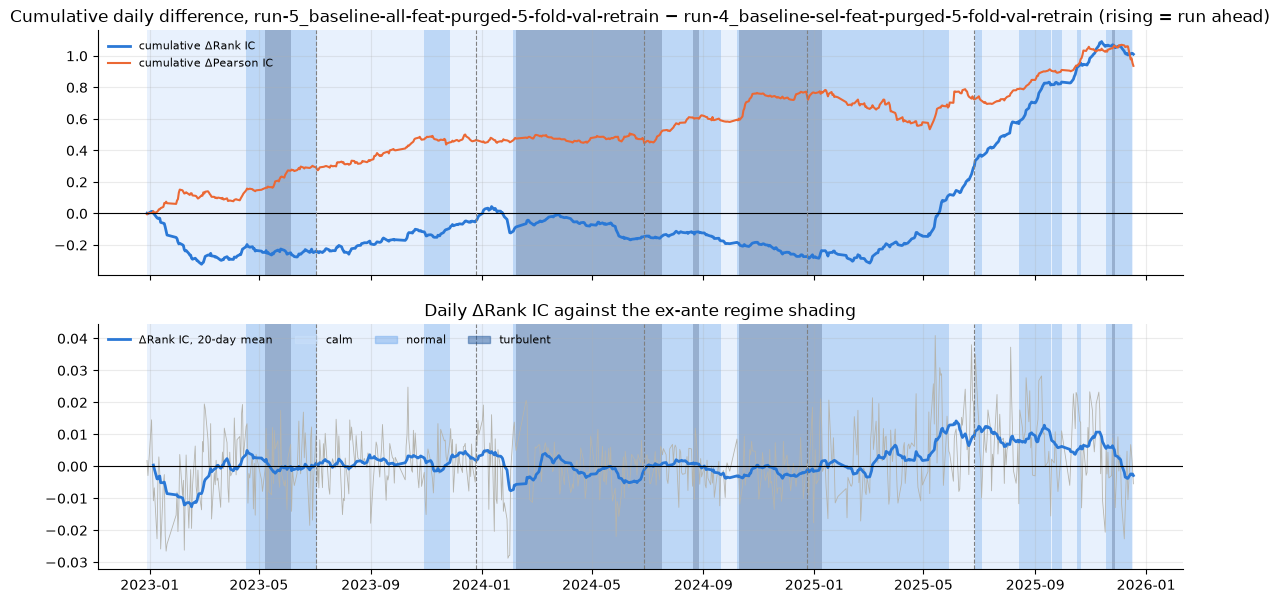

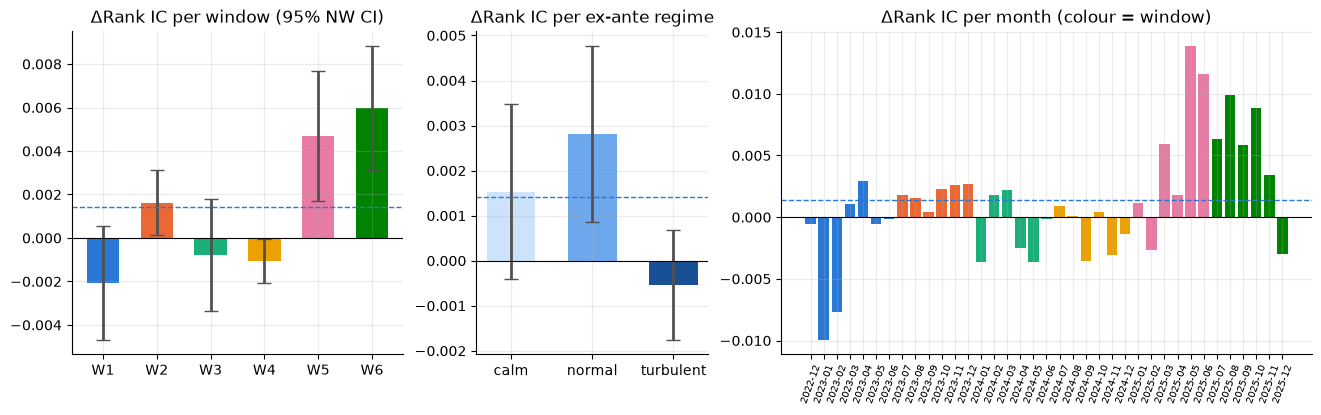

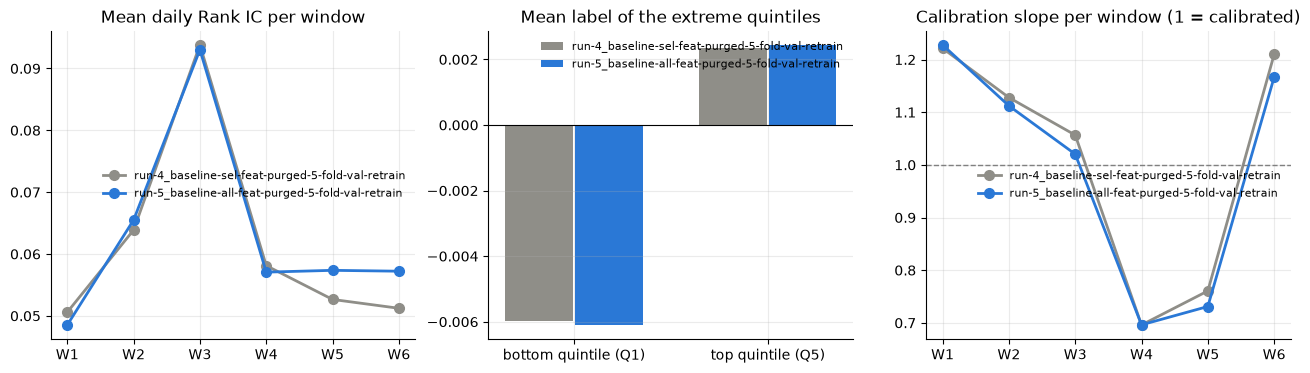

Mean daily prediction agreement (rank corr run vs baseline): 0.935


In [11]:
assert COMPARE, "No baseline set: skip this section."
run_name, base_name = RUN_DIR.name, BASELINE_DIR.name
win_starts = [paired.filter(pl.col("window") == w)["Date"].min() for w in sorted(paired["window"].unique())]

# ---- 1. Where in time does the run gain or lose? ------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
t = paired["Date"].to_numpy()
axes[0].plot(t, paired["d_ric"].fill_nan(0).cum_sum(), color=MODEL_COLORS["run"], label="cumulative ΔRank IC")
axes[0].plot(t, paired["d_ic"].fill_nan(0).cum_sum(), color="#eb6834", lw=1.5, label="cumulative ΔPearson IC")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title(f"Cumulative daily difference, {run_name} − {base_name} (rising = run ahead)")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(t, paired["d_ric"], color="#b5b4ad", lw=0.6)
axes[1].plot(t, paired["d_ric"].rolling_mean(20, min_samples=5), color=MODEL_COLORS["run"],
             label="ΔRank IC, 20-day mean")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Daily ΔRank IC against the ex-ante regime shading")
for ax in axes:
    shade(ax)
    for s in win_starts[1:]:
        ax.axvline(s, color="gray", ls="--", lw=0.8)
axes[1].legend(handles=axes[1].get_legend_handles_labels()[0]
               + [Patch(color=REGIME_COLORS[r], alpha=0.45, label=r) for r in REGIMES],
               loc="upper left", fontsize=8, ncol=4)
save(fig, "compare_timeline")

# ---- 2. Is the gain consistent across windows, regimes, months? ---------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 0.7, 1.6]})
wl = by_window_delta["scope"].to_list()
wcol = [WINDOW_COLORS[int(s[1:]) - 1] for s in wl]
axes[0].bar(wl, by_window_delta["dRankIC"], color=wcol, width=0.6,
            yerr=by_window_delta["95% CI ±"], capsize=5, ecolor="#52514e")
axes[0].set_title("ΔRank IC per window (95% NW CI)")
rl = by_regime_delta["scope"].to_list()
axes[1].bar(rl, by_regime_delta["dRankIC"], color=[REGIME_COLORS[r] for r in rl], width=0.6,
            yerr=by_regime_delta["95% CI ±"], capsize=5, ecolor="#52514e")
axes[1].set_title("ΔRank IC per ex-ante regime")
month_window = paired.group_by("month").agg(pl.col("window").mode().first()).sort("month")
mcol = [WINDOW_COLORS[w - 1] for w in month_window["window"]]
xm = np.arange(by_month_delta.height)
axes[2].bar(xm, by_month_delta["dRankIC"], color=mcol, width=0.8)
axes[2].set_xticks(xm, by_month_delta["month"], rotation=70, fontsize=7)
axes[2].set_title("ΔRank IC per month (colour = window)")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(overall["dRankIC"], color=MODEL_COLORS["run"], ls="--", lw=1)
save(fig, "compare_breakdown")

# ---- 3. Levels and magnitudes for both models ----------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
xw = np.arange(len(wl))
axes[0].plot(xw, by_window_delta["RankIC base"], "o-", color=MODEL_COLORS["baseline"], label=base_name, ms=7)
axes[0].plot(xw, by_window_delta["RankIC run"], "o-", color=MODEL_COLORS["run"], label=run_name, ms=7)
axes[0].set_xticks(xw, wl)
axes[0].set_title("Mean daily Rank IC per window")
qcols = [f"Q{q}" for q in (1, 5)]
qb = [overall["Q1 base"], overall["Q5 base"]]
qr = [overall["Q1 run"], overall["Q5 run"]]
xq = np.arange(2)
axes[1].bar(xq - 0.18, qb, width=0.35, color=MODEL_COLORS["baseline"], label=base_name)
axes[1].bar(xq + 0.18, qr, width=0.35, color=MODEL_COLORS["run"], label=run_name)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(xq, ["bottom quintile (Q1)", "top quintile (Q5)"])
axes[1].set_title("Mean label of the extreme quintiles")
axes[2].plot(xw, facts["slope_base"], "o-", color=MODEL_COLORS["baseline"], label=base_name, ms=7)
axes[2].plot(xw, facts["slope_run"], "o-", color=MODEL_COLORS["run"], label=run_name, ms=7)
axes[2].axhline(1, color="gray", ls="--", lw=1)
axes[2].set_xticks(xw, [f"W{w}" for w in facts["window"]])
axes[2].set_title("Calibration slope per window (1 = calibrated)")
for ax in axes:
    ax.legend(fontsize=8)
save(fig, "compare_levels")
print(f"Mean daily prediction agreement (rank corr run vs baseline): {overall['agreement']:.3f}")


## Findings

**Run 5 on its own**

1. **Overall:** Rank IC 0.0631 (NW t 14.5), Pearson IC 0.0985 (NW t 21.1),
   ICIR 1.37, IC > 0 on 92% of days. Positive in every window (Rank IC
   0.049–0.093), and > 0 on 81–93% of days per window.
2. **Consistency:** medians and trimmed means ≈ means (W5 median 0.085 vs
   mean 0.074: a few bad days).
3. **Pearson vs Rank:** Pearson ≈ 1.56× Rank IC. The edge is in Q1
   (−0.0046 … −0.0089), with Q2–Q5 nearly flat. Unchanged.
4. **Calibration:**
   - Slopes 1.23, 1.11, 1.02, 0.70, 0.73, 1.17; mean |slope − 1| 0.18.
   - Monthly slopes < 0.5 occur in the known hard months: 2023-06, 2023-09,
     2024-02, 2024-09/10, 2025-02, 2025-05.
5. **Val vs test R²:** fold-mean validation R² 0.0058–0.0107 against test
   0.0040–0.0179. W4 and W5 test is below validation (hard test periods).
6. **Regimes:** calm 0.047 ± 0.013 (8 episodes), normal 0.060 ± 0.012 (11),
   turbulent 0.091 ± 0.018 (3 episodes).

**Comparison with run 4 (paired, 2,028,817 rows)**

7. **Ranking: small but significant gain, uneven across windows.**
   - ΔRank IC **+0.0014 ± 0.0011** (t 2.5), run better on 55% of days.
     ΔPearson IC +0.0013, ΔQ5−Q1 +0.0002.
   - Positive in 3 of 6 windows: W5 +0.0047 (t 3.1), W6 +0.0060 (t 4.1) and
     W2 +0.0016 (t 2.1).
   - Negative: W1 −0.0021 (t −1.6), W4 −0.0011 (t −2.0), W3 −0.0008.
   - The cumulative difference is flat or slightly negative until 2025-02,
     then rises steadily: the gain is a **2025 effect** (2025-03…11).
   - Regimes: normal +0.0028 (significant), calm +0.0015, turbulent −0.0005
     (both CIs include 0).
8. **Tree counts are not the cause.** Run 5's saved models scored at run 4's
   tree counts give Rank IC within 0.0006 of their own counts, e.g. W5 0.0577
   at 273 trees vs 0.0574 at 286; W6 0.0577 vs 0.0572. So the differences
   come from the features.
9. **Why the extra features can help:**
   - The filter dropped 8–15 features per window.
   - In the test periods their mean |daily Rank IC with the label| is
     0.015–0.028, often higher than in training. Single features reach 0.069
     (W5) and 0.048 (W6).
   - Linear correlation over the history is a poor guide to what the trees
     can use later.
   - W5 and W6 dropped the most (14 and 15) and gained the most. But W1 also
     dropped 14 and lost slightly, so this is not a rule.
10. **Magnitudes: slightly better.**
    - Pooled R² 0.0085 → 0.0088 (+3%); better in 5 of 6 windows (W5 0.00417
      → 0.00404).
    - Calibration unchanged (mean |slope − 1| 0.19 → 0.18); RMSE equal.
11. **Agreement:** 0.94 overall; 0.88 in W5, 0.91–0.97 elsewhere. A modest
    change of the model.
12. **Cost:** runtime +10%, memory the same.

**Verdict:**
- **Slightly better, but not consistently.** The overall ΔRank IC excludes 0
  (t 2.5) and R² is better in 5 of 6 windows.
- The strict "better" rule (positive in ≥ 5 of 6 windows) is **not met**:
  the ranking gain is concentrated in 2025.
- The validation curves agreed (N-17: fold-mean val R² higher in 5 of 6
  windows).
- Recommendation: **adopt all features as the reference.** It is simpler
  (no `CORR_BAR`, no selection instability), and no worse anywhere by more
  than noise.
- Caveat: four variants have now been compared on the same windows, and seed
  noise is unmeasured.

**Leaderboard (section 15):** run 5 has the best headline value in all five
metrics (Rank IC 0.0631, Pearson 0.0985, Kendall 0.0424, R² 0.00879, ICIR
1.42). Per window, run 5 leads Rank IC in 2 of 6 windows and R² in 5 of 6.

**Open questions:**
- Is +0.0014 above seed noise?
- Does the 2025 gain persist (only the reserved final window can tell, at
  the end)?


## Summary: run 5 (all features) vs run 4 (feature filter)

**Setup.**
- Only change: no `CORR_BAR` filter, so all 48 features. Same purged 5-fold
  protocol.
- 6 windows, 720 test dates. Final window held back.

**Overall performance.**
- Ranking: Rank IC 0.0631 (Pearson 0.0985), ICIR 1.37, IC > 0 on 92% of
  days, NW t 14.5 / 21.1. Q5−Q1 0.005–0.014 (gross, label units).
- Magnitude: R² 0.0088, slopes 0.70–1.23 (mean |slope − 1| 0.18). Runtime
  663 s.

**Comparison with the baseline.**
- ΔRank IC +0.0014 ± 0.0011 (t 2.5), better on 55% of days, but only in 3 of
  6 windows. The gain sits in 2025 (W5 +0.005, W6 +0.006); W1/W4 are
  slightly negative.
- R² +3% (5 of 6 windows), calibration unchanged. Agreement 0.94.
- **Verdict: slightly better, not consistent across windows.** Adopt as the
  reference for simplicity.

**Where it excels.**
- 2025 (Mar–Nov): weakly correlated features carry signal there.
- Best on every headline metric in the leaderboard of runs 2–5.

**Where it stumbles.**
- Early 2023 (W1) and W4: small losses.
- Overconfident W4/W5 as always (hard test periods).

**Probable reasons.**
1. Features dropped by the linear filter still carry information in some
   periods (test daily |Rank IC| up to 0.069).
2. Inputs are stable instead of re-selected per fold.
3. The test period still drives the levels. Tree count is not a factor here
   (checked).

**What this run achieved and what to try next.**
- New reference: all features, purged 5-fold.
- Next: seed noise (T-4), the out-of-fold scale correction (T-3),
  GOSS → bagging (T-5), label clipping (T-6).

**Hypotheses in brief.**
- Helped: features with weak or time-varying linear correlation.
- Hurt: possibly slightly more noise fitting in W1/W4.
- Didn't matter: tree-count differences.


## Hypotheses: what drove the difference vs run 4

**Likely improvements.**
1. **The filter dropped useful, time-varying features.**
   - Mechanism: `CORR_BAR` keeps a feature only if its linear correlation
     over the history exceeds 0.02. Features whose relation is non-linear,
     interaction-based, or that strengthen later are dropped.
   - Evidence:
     - The dropped features' test-period daily |Rank IC| is 0.015–0.028 on
       average (up to 0.069), often above their training level.
     - The gains are largest where the most features were dropped (W5: 14,
       W6: 15).
     - The validation curves agree (N-17).
   - Confidence: medium. W1 also dropped 14 and lost slightly.
2. **Stable inputs.**
   - Mechanism: the same 48 features in every fold and in the retrain, so
     validation measures the same model that gets deployed.
   - Evidence: in run 4, per-fold sets ranged from 24 to 43 features, and
     the largest validation gains are in W5 (27–41) and W6 (24–37).
   - Confidence: low to medium; it overlaps with hypothesis 1.

**Likely degradations.**
1. **More capacity, slightly more noise fitting in some periods.**
   - Evidence: fold-mean training R² is higher (e.g. W4 0.026 → 0.030), with
     small losses in W1 (−0.0021) and W4 (−0.0011, t −2.0).
   - Confidence: low; this is within seed-noise range until measured.
2. **Cost:** runtime +10%.

**What matters most / what matters little.**
- Most: **the test period**. The 2025 test months drive the whole gain, and
  window levels still range 0.049–0.093 for every run.
- Then the feature set (+0.0014 overall).
- Little: the tree-count differences (≤ 0.0006 at matched counts) and
  calibration (unchanged).

**Confounding.** None in the setup (a single change). The time
concentration means a regime-specific effect can't be told apart from a
general one with 6 windows.

**Experiments to test them.**
1. Seed noise (T-4): run 4 and run 5 with 2 more seeds each. The gain is real
   if ΔRank IC stays > 0 in every seed pair.
2. Feature-importance check (no training): gain or split counts of the 14–15
   extra features in the W5/W6 models. Hypothesis 1 predicts non-trivial
   usage.
3. Later: `feature_fraction` 0.7 (randomly drop features per tree) could
   reduce any noise fitting from the extra features.


## Leaderboard: runs side by side

Each run's **own** test-set metrics on the same 720 test dates. In each
column (first table) or row (other tables), the best value is **bold**.

- **Rank IC, Pearson IC, Kendall:** means of the daily values over all test
  dates. Kendall is daily, unlike the training script's pooled `kt` (I-4).
- **R²:** pooled over all test rows (first table) or over each window's rows.
- **ICIR:** mean(daily Pearson IC) / std, per window, averaged over the
  windows (unscaled, comparable across windows).

Read with care:
- These are unpaired levels. The paired tests (section 7) are what decide
  significance: a gap of ~0.001 Rank IC is within noise.
- Seed noise is not measured yet.
- Every extra variant compared on the same windows inflates the best one's
  apparent edge.


In [12]:
from IPython.display import Markdown, display

LEADERBOARD_DIRS = ["/workspaces/TimeSeries48/runs/run-2_original-baseline-six-windows", "/workspaces/TimeSeries48/runs/run-3_baseline-chrono-val-plus-retrain", "/workspaces/TimeSeries48/runs/run-4_baseline-sel-feat-purged-5-fold-val-retrain", "/workspaces/TimeSeries48/runs/run-5_baseline-all-feat-purged-5-fold-val-retrain"]  # Run folders to compare (set by the skill).


def short_name(path: Path) -> str:
    """'run-5_baseline-all-feat-...' -> 'run-5'."""
    return path.name.split("_")[0]


def r2_expr() -> pl.Expr:
    """Pooled R² of Prediction for label."""
    resid = ((pl.col("label") - pl.col("Prediction")) ** 2).sum()
    total = ((pl.col("label") - pl.col("label").mean()) ** 2).sum()
    return (1 - resid / total).alias("r2")


def run_summary(run_dir: Path) -> tuple[dict[str, float], pl.DataFrame]:
    """Headline test metrics over all dates, and per-window Rank IC / R² / ICIR."""
    _, p, _ = load_run(run_dir)
    d, _, _ = daily_metrics(p)
    per_window = (
        p.group_by("window").agg(r2_expr())
        .join(d.group_by("window").agg(
            pl.col("rank_ic").mean(),
            (pl.col("ic").mean() / pl.col("ic").std()).alias("icir"),
        ), on="window")
        .sort("window")
    )
    head = {
        "Rank IC": d["rank_ic"].mean(),
        "Pearson IC": d["ic"].mean(),
        "Kendall": d["kendall"].mean(),
        "R² (all rows)": p.select(r2_expr()).item(),
        "ICIR (window mean)": per_window["icir"].mean(),
    }
    return head, per_window


def bold_table(row_names: list[str], col_names: list[str], values: np.ndarray,
               fmts: list[str], best_per: str) -> str:
    """Markdown table; the highest shown value per 'row' or 'column' is bold."""
    shown = [[format(values[i, j], fmts[j if best_per == "column" else 0])
              for j in range(len(col_names))] for i in range(len(row_names))]
    num = np.array([[float(s) for s in row] for row in shown])
    best = num.max(axis=0 if best_per == "column" else 1)
    lines = ["| | " + " | ".join(col_names) + " |",
             "|---|" + "---|" * len(col_names)]
    for i, name in enumerate(row_names):
        cells = [f"**{s}**" if num[i, j] == (best[j] if best_per == "column" else best[i])
                 else s for j, s in enumerate(shown[i])]
        lines.append(f"| {name} | " + " | ".join(cells) + " |")
    return "\n".join(lines)


dirs = [Path(p) for p in LEADERBOARD_DIRS]
if RUN_DIR.resolve() not in [p.resolve() for p in dirs]:
    dirs.append(RUN_DIR)
names = [short_name(p) for p in dirs]
summaries = {name: run_summary(p) for name, p in zip(names, dirs, strict=True)}

metrics = list(next(iter(summaries.values()))[0])
head_values = np.array([[summaries[n][0][m] for m in metrics] for n in names])
head_md = bold_table(names, metrics, head_values,
                     ["0.4f", "0.4f", "0.4f", "0.5f", "0.3f"], best_per="column")

window_rows = [f"W{k + 1} ({r['test_start']} → {r['test_end']})"
               for k, r in enumerate(results)] + ["all test dates"]
rank_ic = np.array([[*summaries[n][1]["rank_ic"].to_list(), summaries[n][0]["Rank IC"]]
                    for n in names]).T
r2 = np.array([[*summaries[n][1]["r2"].to_list(), summaries[n][0]["R² (all rows)"]]
               for n in names]).T
rank_md = bold_table(window_rows, names, rank_ic, ["0.4f"], best_per="row")
r2_md = bold_table(window_rows, names, r2, ["0.5f"], best_per="row")

legend = "\n".join(f"- **{n}**: `{p.name}`" for n, p in zip(names, dirs, strict=True))
text = (f"**Runs**\n\n{legend}\n\n**Headline test metrics** (best per column in bold)\n\n"
        f"{head_md}\n\n**Rank IC per window** (best per row in bold)\n\n{rank_md}\n\n"
        f"**R² per window** (best per row in bold)\n\n{r2_md}")
display(Markdown(text))
print(text)  # Plain text too, for headless runs.


**Runs**

- **run-2**: `run-2_original-baseline-six-windows`
- **run-3**: `run-3_baseline-chrono-val-plus-retrain`
- **run-4**: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`
- **run-5**: `run-5_baseline-all-feat-purged-5-fold-val-retrain`

**Headline test metrics** (best per column in bold)

| | Rank IC | Pearson IC | Kendall | R² (all rows) | ICIR (window mean) |
|---|---|---|---|---|---|
| run-2 | 0.0581 | 0.0945 | 0.0389 | 0.00762 | 1.395 |
| run-3 | 0.0624 | 0.0961 | 0.0420 | 0.00803 | 1.379 |
| run-4 | 0.0617 | 0.0972 | 0.0414 | 0.00850 | 1.392 |
| run-5 | **0.0631** | **0.0985** | **0.0424** | **0.00879** | **1.417** |

**Rank IC per window** (best per row in bold)

| | run-2 | run-3 | run-4 | run-5 |
|---|---|---|---|---|
| W1 (2022-12-29 → 2023-06-30) | 0.0450 | **0.0527** | 0.0506 | 0.0485 |
| W2 (2023-07-03 → 2023-12-25) | 0.0590 | 0.0603 | 0.0639 | **0.0655** |
| W3 (2023-12-26 → 2024-06-27) | 0.0900 | 0.0934 | **0.0938** | 0.0930 |
| W4 (2024-06-28 → 2024-12-23) | 0.0556 | 0.0552 | **0.0581** | 0.0571 |
| W5 (2024-12-24 → 2025-06-25) | 0.0520 | **0.0610** | 0.0527 | 0.0574 |
| W6 (2025-06-26 → 2025-12-18) | 0.0469 | 0.0519 | 0.0512 | **0.0572** |
| all test dates | 0.0581 | 0.0624 | 0.0617 | **0.0631** |

**R² per window** (best per row in bold)

| | run-2 | run-3 | run-4 | run-5 |
|---|---|---|---|---|
| W1 (2022-12-29 → 2023-06-30) | 0.00735 | 0.00777 | 0.00832 | **0.00897** |
| W2 (2023-07-03 → 2023-12-25) | 0.01080 | 0.01064 | 0.01079 | **0.01113** |
| W3 (2023-12-26 → 2024-06-27) | 0.01694 | 0.01736 | 0.01772 | **0.01793** |
| W4 (2024-06-28 → 2024-12-23) | 0.00363 | 0.00499 | 0.00462 | **0.00500** |
| W5 (2024-12-24 → 2025-06-25) | 0.00227 | 0.00342 | **0.00417** | 0.00404 |
| W6 (2025-06-26 → 2025-12-18) | 0.00640 | 0.00515 | 0.00668 | **0.00709** |
| all test dates | 0.00762 | 0.00803 | 0.00850 | **0.00879** |

**Runs**

- **run-2**: `run-2_original-baseline-six-windows`
- **run-3**: `run-3_baseline-chrono-val-plus-retrain`
- **run-4**: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`
- **run-5**: `run-5_baseline-all-feat-purged-5-fold-val-retrain`

**Headline test metrics** (best per column in bold)

| | Rank IC | Pearson IC | Kendall | R² (all rows) | ICIR (window mean) |
|---|---|---|---|---|---|
| run-2 | 0.0581 | 0.0945 | 0.0389 | 0.00762 | 1.395 |
| run-3 | 0.0624 | 0.0961 | 0.0420 | 0.00803 | 1.379 |
| run-4 | 0.0617 | 0.0972 | 0.0414 | 0.00850 | 1.392 |
| run-5 | **0.0631** | **0.0985** | **0.0424** | **0.00879** | **1.417** |

**Rank IC per window** (best per row in bold)

| | run-2 | run-3 | run-4 | run-5 |
|---|---|---|---|---|
| W1 (2022-12-29 → 2023-06-30) | 0.0450 | **0.0527** | 0.0506 | 0.0485 |
| W2 (2023-07-03 → 2023-12-25) | 0.0590 | 0.0603 | 0.0639 | **0.0655** |
| W3 (2023-12-26 → 2024-06-27) | 0.0900 | 0.0934 | **0.0938** | 0.0930 |
| W4 (2024-06-28 → 2024-12-23) | 0.0